# L'ensemble de Mandelbrot 

**Objectif**: calculer l’image de la convergence de Mandelbrot

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## v1

In [2]:
# à vous de jouer

def mandelbrot(h, w, max_iter=20):
    x = np.linspace(-2, 0.8, w)    #partie réelle
    y = np.linspace(-1.4, 1.4, h)  #partie imaginaire
    X, Y = np.meshgrid(x, y)

    C = np.dstack((X, Y))          #forme (h, w, 2) avec C[i, j] = (x, y)
    Z = np.zeros((h, w, 2))        

    diverge = np.full((h, w), max_iter)   #valeur par défaut = ne diverge pas

    for n in range(max_iter):
        actifs = diverge == max_iter       #cases qui n'ont pas encore divergé

        zx, zy = Z[actifs, 0], Z[actifs, 1]
        cx, cy = C[actifs, 0], C[actifs, 1]

        Z[actifs, 0] = zx**2 - zy**2 + cx
        Z[actifs, 1] = 2 * zx * zy + cy

        sort = Z[:,:,0]**2 + Z[:,:,1]**2 > 4
        diverge[actifs & sort] = n

    plt.imshow(diverge, extent=(-2, 0.8, -1.4, 1.4), origin="lower")
    plt.colorbar()
    plt.show()

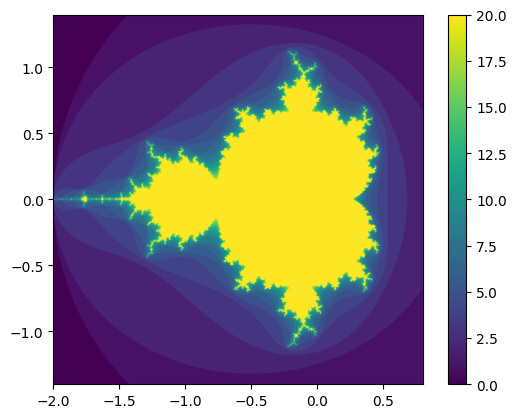

In [3]:
# et pour la tester, pour produire la mème figure que ci-dessus

mandelbrot(1000, 1000)

## v2

on peut passer en paramètre à la fonction

- le domaine en x et en y

- le nombre maximum d’itérations

on veut pouvoir produire une image (pour l’insérer dans l’énoncé par exemple)

- quels formats sont disponibles ?

- sauvez votre image dans un format vectoriel

- affichez cette depuis votre notebook

In [4]:
def mandelbrot2(h, w, xlim=(-2, 0.8), ylim=(-1.4, 1.4), max_iter=20,
                fichier=None, afficher=True):
    x = np.linspace(xlim[0], xlim[1], w)
    y = np.linspace(ylim[0], ylim[1], h)
    X, Y = np.meshgrid(x, y)

    C = np.dstack((X, Y))
    Z = np.zeros((h, w, 2))
    diverge = np.full((h, w), max_iter)

    for n in range(max_iter):
        actifs = diverge == max_iter
        zx, zy = Z[actifs, 0], Z[actifs, 1]
        cx, cy = C[actifs, 0], C[actifs, 1]
        Z[actifs, 0] = zx**2 - zy**2 + cx
        Z[actifs, 1] = 2 * zx * zy + cy
        sort = Z[:, :, 0]**2 + Z[:, :, 1]**2 > 4
        diverge[actifs & sort] = n

    fig, ax = plt.subplots(layout="constrained")
    im = ax.imshow(diverge, extent=(*xlim, *ylim), origin="lower",
                   interpolation="none")     
    fig.colorbar(im, ax=ax)

    if fichier is not None:
        fig.savefig(fichier)
    if afficher:
        plt.show()
    else:
        plt.close(fig)                      
    return diverge

### Quels formats sont disponibles ?

In [5]:
from matplotlib.backend_bases import FigureCanvasBase
print(FigureCanvasBase.get_supported_filetypes())

{'eps': 'Encapsulated Postscript', 'jpg': 'Joint Photographic Experts Group', 'jpeg': 'Joint Photographic Experts Group', 'pdf': 'Portable Document Format', 'pgf': 'PGF code for LaTeX', 'png': 'Portable Network Graphics', 'ps': 'Postscript', 'raw': 'Raw RGBA bitmap', 'rgba': 'Raw RGBA bitmap', 'svg': 'Scalable Vector Graphics', 'svgz': 'Scalable Vector Graphics', 'tif': 'Tagged Image File Format', 'tiff': 'Tagged Image File Format', 'webp': 'WebP Image Format'}


Quelques tests de votre deuxième fonction

In [6]:
from IPython.display import SVG, display

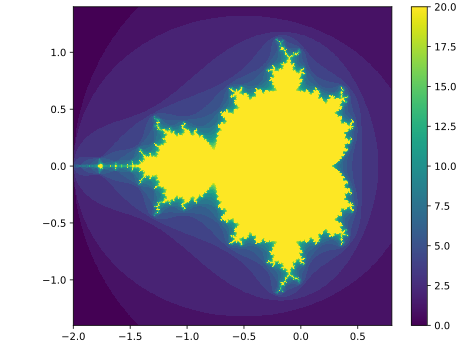

In [7]:
# test #1

mandelbrot2(1000, 1000, fichier="test1.svg", afficher=False)
SVG(filename="test1.svg")

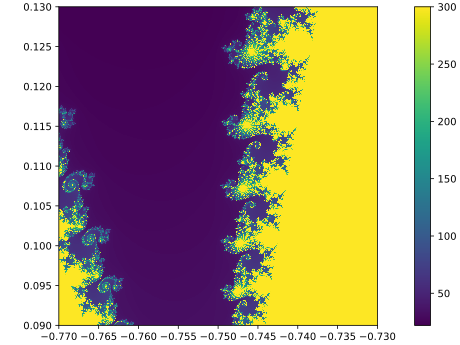

In [8]:
# test #2

mandelbrot2(1000, 1000, xlim=(-0.77, -0.73), ylim=(0.09, 0.13),
            max_iter=300, fichier="test2.svg", afficher=False)
SVG(filename="test2.svg")

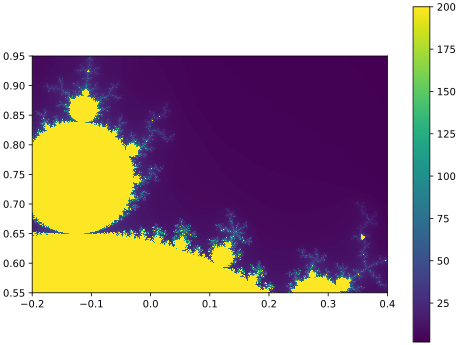

In [9]:
# test #3

mandelbrot2(600, 900, xlim=(-0.2, 0.4), ylim=(0.55, 0.95),
            max_iter=200, fichier="test3.svg", afficher=False)
SVG(filename="test3.svg")